# Bab 8 — Learning Signal and Ignoring Noise: Regularization and Batching

**Acuan:** Trask, *Grokking Deep Learning*, Bab 8, hlm. 145–160. Buku memakai MNIST 28×28; notebook ini memakai **`load_digits` 8×8 bawaan scikit-learn** agar dapat dijalankan offline tanpa mengunduh dataset. Kode jaringan, dropout, dan loop mini-batch ditulis mandiri.

**Tujuan belajar:** memisahkan training/validation/test, mengenali overfitting, memahami early stopping dan dropout, serta melakukan pembaruan mini-batch.

## 1. Data dan risiko memorisasi

Model yang makin fleksibel dapat mempelajari detail khusus training set yang tidak berulang pada contoh baru. Karena itu, bandingkan loss/akurasi training dengan data **validation** yang tidak dipakai untuk pembaruan bobot. Test set disimpan untuk evaluasi akhir setelah pilihan model/epoch dibuat. Dataset digit ini hanya demonstrasi, bukan reproduksi numerik hasil MNIST dalam buku.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits

digits = load_digits()
rng_split = np.random.default_rng(20)
order = rng_split.permutation(len(digits.data))
train_idx, val_idx, test_idx = order[:180], order[180:600], order[600:]
X_all = digits.data / 16.0  # intensitas piksel maksimum bawaan dataset adalah 16
Y_all = np.eye(10)[digits.target]
X_train, Y_train = X_all[train_idx], Y_all[train_idx]
X_val, Y_val = X_all[val_idx], Y_all[val_idx]
X_test, Y_test = X_all[test_idx], Y_all[test_idx]
print('Train/validation/test:', X_train.shape, X_val.shape, X_test.shape)
assert len(set(train_idx) & set(val_idx)) == 0
assert len(set(test_idx) & set(val_idx)) == 0

Train/validation/test: (180, 64) (420, 64) (1197, 64)


## 2. Jaringan tiga layer dan loss

Input berukuran 64 (8×8 piksel), hidden layer 64 unit ReLU, output 10 skor kelas. Bab ini mempertahankan output linear dan squared error seperti tahap buku sebelum softmax dikenalkan di Bab 9. Untuk satu batch berukuran $m$, $L=\frac1m\sum_i\sum_c(s_{ic}-y_{ic})^2$. Prediksi kelas memakai `argmax` skor, bukan menganggap skor sebagai probabilitas. Tanpa dropout, gradien hidden mengikuti chain rule dari Bab 6.

In [2]:
def initialize(seed=4):
    rng = np.random.default_rng(seed)
    return [rng.normal(0, .06, (64, 64)), np.zeros((1, 64)),
            rng.normal(0, .06, (64, 10)), np.zeros((1, 10))]

def predict_scores(X, params):
    W1, b1, W2, b2 = params
    hidden = np.maximum(0, X @ W1 + b1)
    return hidden @ W2 + b2

def evaluate(X, Y, params):
    scores = predict_scores(X, params)
    loss = np.mean(np.sum((scores - Y) ** 2, axis=1))
    accuracy = np.mean(scores.argmax(axis=1) == Y.argmax(axis=1))
    return float(loss), float(accuracy)

start = initialize()
print('Loss/akurasi awal training:', tuple(round(v, 3) for v in evaluate(X_train, Y_train, start)))

Loss/akurasi awal training: (1.022, 0.1)


## 3. Mini-batch dan inverted dropout

Mini-batch memakai sebagian baris untuk setiap pembaruan. Stochastic gradient descent memakai satu baris, full-batch memakai seluruh training set; mini-batch ada di antaranya. Saat training dengan dropout probabilitas $p$, sebagian aktivasi hidden dibuat nol dan yang tersisa dibagi $1-p$ (*inverted dropout*). Skala ini membuat rata-rata aktivasi sebanding saat inference, ketika dropout dimatikan. Mask yang sama harus dipakai pada backprop untuk unit yang dimatikan. Dropout tidak dijalankan pada validation/test.

Early stopping memilih epoch berdasarkan validation loss, bukan training loss. Mengintip test set untuk memilih epoch akan membuat evaluasi test menjadi bias.

In [3]:
def train_network(dropout_rate=0.0, epochs=130, batch_size=30, lr=.035, seed=4):
    params = initialize(seed)
    rng = np.random.default_rng(seed + 100)
    history = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}
    best_params, best_epoch, best_val = None, None, float('inf')
    for epoch in range(epochs):
        for indices in np.array_split(rng.permutation(len(X_train)),
                                      int(np.ceil(len(X_train) / batch_size))):
            xb, yb = X_train[indices], Y_train[indices]
            W1, b1, W2, b2 = params
            z1 = xb @ W1 + b1
            h = np.maximum(0, z1)
            mask = (rng.random(h.shape) >= dropout_rate) / (1 - dropout_rate)
            h_train = h * mask
            scores = h_train @ W2 + b2
            ds = 2 * (scores - yb) / len(xb)
            gW2 = h_train.T @ ds
            gb2 = ds.sum(axis=0, keepdims=True)
            dz1 = (ds @ W2.T) * (z1 > 0) * mask
            gW1 = xb.T @ dz1
            gb1 = dz1.sum(axis=0, keepdims=True)
            params = [W1 - lr*gW1, b1 - lr*gb1, W2 - lr*gW2, b2 - lr*gb2]
        tr_loss, tr_acc = evaluate(X_train, Y_train, params)
        va_loss, va_acc = evaluate(X_val, Y_val, params)
        for key, value in zip(history, [tr_loss, va_loss, tr_acc, va_acc]):
            history[key].append(value)
        if va_loss < best_val:
            best_val, best_epoch = va_loss, epoch
            best_params = [array.copy() for array in params]
    return history, best_params, best_epoch

plain_history, plain_best, plain_epoch = train_network(dropout_rate=0.0)
drop_history, drop_best, drop_epoch = train_network(dropout_rate=.35)
print('Epoch validation terbaik, tanpa/dengan dropout:', plain_epoch, drop_epoch)
print('Validation loss terbaik:', round(min(plain_history['val_loss']), 3),
      round(min(drop_history['val_loss']), 3))

Epoch validation terbaik, tanpa/dengan dropout: 128 127
Validation loss terbaik: 0.266 0.235


## 4. Baca kurva, lalu evaluasi test sekali

Jika training loss terus turun sedangkan validation loss berbalik naik, kapasitas model mulai menangkap detail yang tidak membantu generalisasi. Di notebook ini `best_params` menyimpan keadaan pada validation loss minimum: itulah bobot yang akan dipakai jika early stopping dilakukan. Dropout dapat memperkecil gap, tetapi **tidak dijamin** mengungguli model tanpa dropout pada setiap dataset, seed, dan hyperparameter. Jangan memilih pemenang dengan membandingkan test berulang kali.

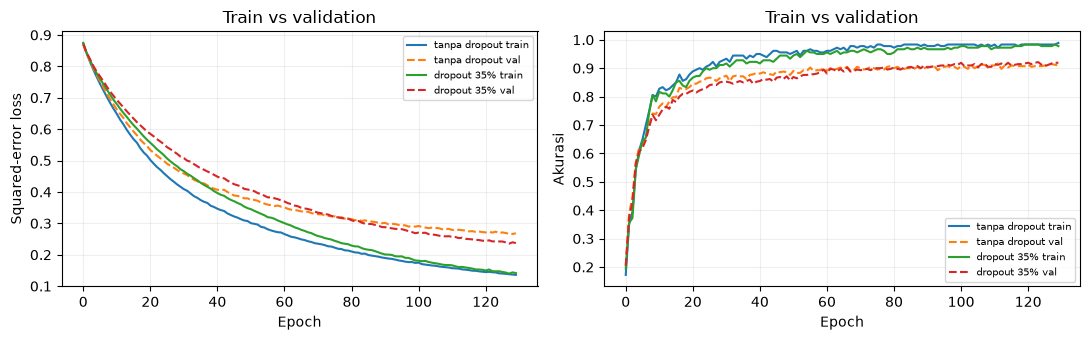

tanpa dropout test loss: 0.276 test accuracy: 0.906
dropout test loss: 0.249 test accuracy: 0.901


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for name, hist in [('tanpa dropout', plain_history), ('dropout 35%', drop_history)]:
    axes[0].plot(hist['train_loss'], label=f'{name} train')
    axes[0].plot(hist['val_loss'], linestyle='--', label=f'{name} val')
    axes[1].plot(hist['train_acc'], label=f'{name} train')
    axes[1].plot(hist['val_acc'], linestyle='--', label=f'{name} val')
axes[0].set(xlabel='Epoch', ylabel='Squared-error loss', title='Train vs validation')
axes[1].set(xlabel='Epoch', ylabel='Akurasi', title='Train vs validation')
for ax in axes: ax.legend(fontsize=7); ax.grid(alpha=.2)
plt.tight_layout(); plt.show()
for name, model in [('tanpa dropout', plain_best), ('dropout', drop_best)]:
    loss, accuracy = evaluate(X_test, Y_test, model)
    print(name, 'test loss:', round(loss, 3), 'test accuracy:', round(accuracy, 3))
assert np.isfinite(min(drop_history['val_loss']))

### Ringkasan dan refleksi

- Training loss saja tidak mengukur kemampuan pada gambar baru.
- Early stopping memakai validation set untuk memilih keadaan model; test set tetap di luar proses pemilihan.
- Dropout memaksa jaringan tidak selalu mengandalkan unit hidden tertentu; saat inference mask dimatikan.
- Mini-batch menyeimbangkan frekuensi pembaruan dan stabilitas gradien. Hasil pada `load_digits` tidak dapat langsung dibandingkan dengan akurasi MNIST buku karena ukuran dan karakter data berbeda.